# Robust Income Estimation for Coffee Farmers: A Bootstrap Study

| | |
|---|---|
| **Type** | Statistics / computational inference report (27-page R Markdown → PDF) |
| **Domain** | Agricultural economics · Bukidnon, Philippines |
| **Tools** | R, `boot`, `ggplot2`, `patchwork`, `moments`, `dplyr`, knitr / xelatex |
| **Date** | 2025 |
| **Repository** | [RenzWoo/coffee-bootstrap](https://github.com/RenzWoo/coffee-bootstrap) |

:::{tip} TL;DR
Coffee-farm income is right-skewed and includes losses, which breaks the normality assumption behind classical confidence intervals. This study uses **bootstrap resampling** (5,000 resamples) on a synthetic dataset of 200 farmers to compare parametric, percentile, and **BCa** intervals, then stress-tests them with outliers, small samples, a convergence study, clustering by barangay, and subgroup analysis by coffee variety.
:::

<div class="stats-grid">
<div class="stat-card"><div class="stat-num">200</div><div class="stat-desc">farmers across 18 barangays (synthetic)</div></div>
<div class="stat-card"><div class="stat-num">5,000</div><div class="stat-desc">bootstrap resamples (B), chosen via convergence study</div></div>
<div class="stat-card"><div class="stat-num">1.10</div><div class="stat-desc">skewness of raw income (right-skewed)</div></div>
<div class="stat-card"><div class="stat-num">21.5%</div><div class="stat-desc">of farmers at a net loss</div></div>
</div>

## 1. Problem Statement

Smallholder farm income is volatile, skewed, and sometimes negative. A textbook *t*-interval assumes the
sampling distribution of the mean is roughly normal and symmetric, which can misrepresent uncertainty when
data are skewed, outliers are present, or subgroups are small.

**Research questions**

1. How do bootstrap intervals differ from parametric *t*-intervals (width, symmetry, bias correction)?
2. How does the bootstrap sampling distribution of the mean behave under skew, outliers, and negative values?
3. How many resamples are enough for stable intervals?
4. *When* does BCa give a practical advantage (sample size, skewness, outliers)?
5. Can bootstrap remain informative for small subgroups such as coffee varieties?
6. How sensitive are the results to the independence assumption within barangays, and what does synthetic
   data mean for external validity?

## 2. Data & Storage

| Item | Details |
|---|---|
| **Source** | **Synthetic**, generated to mirror documented properties of smallholder coffee income (right skew, net losses, variety differences). Real farm finances were avoided for ethical and logistical reasons. |
| **Format** | Flat CSV (`bukidnon_coffee_farmers_200_generated.csv`), read with `read.csv` |
| **Size** | 200 rows; farmer-level records across 18 barangays |
| **Variables** | Farm size (ha), coffee variety (Arabica, Robusta, Liberica), annual production (kg), market price per kg, operating costs, **net annual income (PHP)**, barangay |
| **Reproducibility** | `set.seed(42)`; global `B = 5000`, `N_SIM = 1000`; whole analysis knitted to PDF with fixed parameters |
| **Outputs** | Report PDF + R Markdown source in the repository |

**Raw income profile**

| Statistic | Value (PHP) | Statistic | Value |
|---|---|---|---|
| Mean | 42,759.55 | Skewness | 1.10 |
| Median | 27,201.50 | Kurtosis | 3.87 |
| Std. dev. | 55,599.95 | Coeff. of variation | 1.30 |
| IQR | 70,227.75 | % at net loss | 21.5% |
| Min / Max | −41,208 / 227,952 | Mean − median gap | ≈ 15,558 |

## 3. Preprocessing & Data Handling

The data are already tidy, so the work is in **structuring the resampling units**:

- Extract the income vector and profile it: mean/median gap, skewness, kurtosis, share of negative values.
- **Verify the algorithm:** a hand-written bootstrap loop (`sample(..., replace = TRUE)`) was checked against
  `boot::boot()`; the means differ by only PHP 73.78.
- **Slice by group:** subsets by `Coffee_Type` for variety-level intervals, and by `Barangay` to build resampling blocks.
- **Create stress-test datasets:** a copy without the top 5% of incomes, and random sub-samples of n = 20, 40, 60, 80.
- **Track resampling internals:** a 1,000 × 200 selection-count matrix records how often each farmer is drawn per resample.

## 4. Method

| Component | Design |
|---|---|
| **Bootstrap** | Resample 200 incomes with replacement B = 5,000 times; statistic = mean |
| **Interval types** | Parametric *t*; percentile; **BCa** (bias-correction z₀ + acceleration *a* from jackknife influence values) |
| **Four diagnostic experiments** | (1) moment shifts across resamples, (2) density shape, (3) observation-level selection frequency vs. Poisson(1), (4) variance decomposition |
| **Stress tests** | Outlier removal and small sub-samples (an extreme-skewness test is outlined in the methods but not reported) |
| **Convergence study** | B from 200 to 8,000 in steps of 200, 20 independent runs per B |
| **Block bootstrap** | Resample whole **barangays** to test the independence assumption |
| **Subgroups & median** | BCa intervals per coffee variety; bootstrap of the median as a robust alternative |

## 5. Results

### 5.1 Confidence intervals for mean annual income (95%)

| Method | Lower | Upper | Width | Asymmetry | Bias adj. |
|---|---|---|---|---|---|
| Parametric (*t*) | 35,007 | 50,512 | 15,506 | 0 | No |
| Bootstrap percentile | 34,980 | 50,606 | 15,626 | 67 | No |
| **Bootstrap BCa** | **35,481** | **51,029** | 15,548 | **990** | **Yes** |

All three intervals have nearly the **same width**. The BCa difference is that it is **shifted and asymmetric**,
extending further above the mean to reflect the right-skewed sampling distribution.

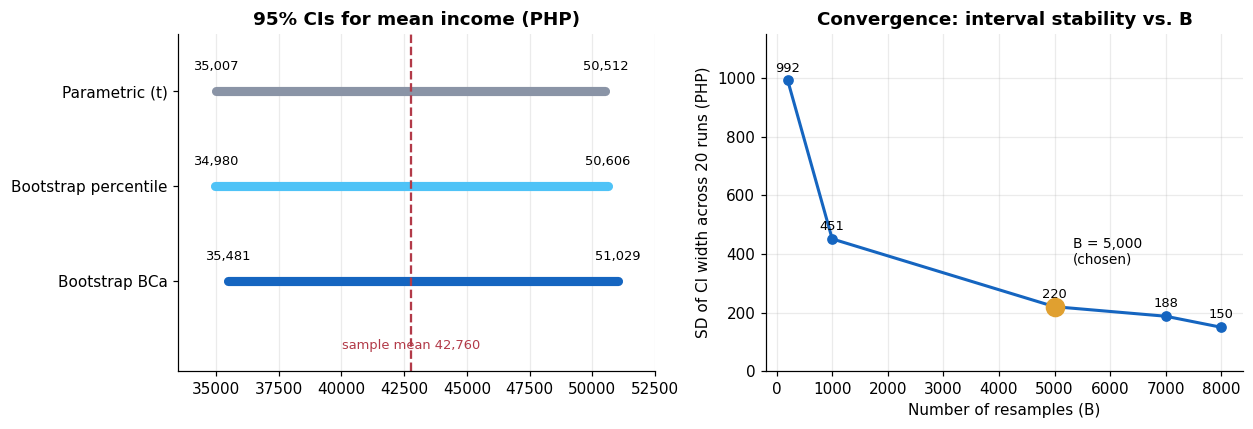

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NAVY, BLUE, SKY, GOLD, RED, GREY = "#0A2540", "#1565C0", "#4FC3F7", "#E0A030", "#B23A48", "#8A94A6"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10,
})

# Transcribed from the report tables (Table 5 and Table 6)
ci = pd.DataFrame({
    "method": ["Parametric (t)", "Bootstrap percentile", "Bootstrap BCa"],
    "lo": [35006.78, 34980.27, 35480.64],
    "hi": [50512.32, 50606.17, 51028.89],
})
mean_income = 42759.55
conv = pd.DataFrame({"B": [200, 1000, 5000, 7000, 8000],
                     "sd_width": [992.39, 451.43, 220.13, 187.53, 149.81]})

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))

ax = axes[0]
ypos = np.arange(len(ci))[::-1]
for y, (_, r), c in zip(ypos, ci.iterrows(), [GREY, SKY, BLUE]):
    ax.plot([r.lo, r.hi], [y, y], color=c, lw=6, solid_capstyle="round")
    ax.text(r.lo, y + 0.22, f"{r.lo:,.0f}", ha="center", fontsize=8.5)
    ax.text(r.hi, y + 0.22, f"{r.hi:,.0f}", ha="center", fontsize=8.5)
ax.axvline(mean_income, color=RED, ls="--", lw=1.5)
ax.text(mean_income, -0.72, f"sample mean {mean_income:,.0f}", color=RED, ha="center", fontsize=8.5)
ax.set_yticks(ypos); ax.set_yticklabels(ci.method)
ax.set_ylim(-0.95, 2.6); ax.set_xlim(33500, 52500)
ax.set_title("95% CIs for mean income (PHP)")
ax.grid(axis="y", alpha=0)

ax = axes[1]
ax.plot(conv.B, conv.sd_width, "o-", color=BLUE, lw=2)
ax.scatter([5000], [220.13], s=140, color=GOLD, zorder=5)
ax.annotate("B = 5,000\n(chosen)", (5000, 220.13), textcoords="offset points", xytext=(12, 28), fontsize=9)
for b, v in zip(conv.B, conv.sd_width):
    ax.text(b, v + 30, f"{v:,.0f}", ha="center", fontsize=8.5)
ax.set_xlabel("Number of resamples (B)"); ax.set_ylabel("SD of CI width across 20 runs (PHP)")
ax.set_title("Convergence: interval stability vs. B")
ax.set_ylim(0, 1150)
plt.tight_layout()
plt.show()

### 5.2 What the four diagnostic experiments showed

| Experiment | Result | Interpretation |
|---|---|---|
| Moment shifts | Resamples reproduce the parent shape (skew ≈ 1.1), but the **distribution of the resampled mean has skewness 0.044** | Empirical demonstration of the Central Limit Theorem |
| Selection frequency | Single resample: ~63% unique farmers, ~37% out-of-bag; counts match **Poisson(1)** (e.g. 74 observed vs. 73.6 expected never-selected) | Resampling is uniform, with no favouritism toward high or low incomes |
| Variance decomposition | Bootstrap SE 3,968 vs. parametric SE 3,932 (ratio **1.009**) | For the mean at n = 200, the methods agree closely on spread |
| Convergence | CI-width SD falls from 992 (B = 200) to **220 (B = 5,000)**, then improves only slowly | B = 5,000 is a sensible cost/stability trade-off |

### 5.3 Stress tests, blocks, and median

| Test | Finding |
|---|---|
| **Remove top 5% outliers** | BCa width 15,353 → 12,729 and asymmetry 1,086 → 452, so BCa's asymmetry is driven by the right tail |
| **Small samples** | BCa width grows honestly as n shrinks: **56,991** (n = 20) → 43,228 (40) → 29,991 (60) → 22,328 (80) |
| **Block bootstrap by barangay** | Width 13,427 vs. 15,548 for the standard bootstrap (~2,100 PHP difference) |
| **Median vs. mean** | Median 27,202 with BCa 16,415–39,389 (width 22,974) vs. mean width 15,548; the median is less sensitive to the tail but noisier |

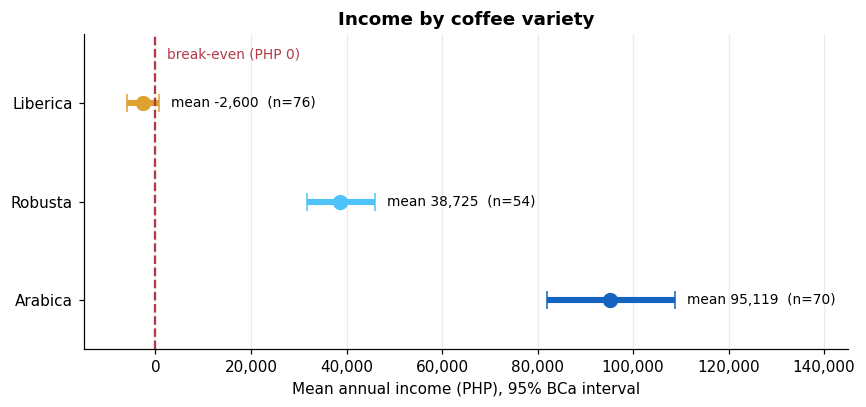

In [2]:
# Subgroup BCa intervals transcribed from the report (Table 9)
sub = pd.DataFrame({
    "variety": ["Arabica", "Robusta", "Liberica"],
    "n": [70, 54, 76],
    "mean": [95119.49, 38725.43, -2600.36],
    "lo": [82003.81, 31649.52, -5864.94],
    "hi": [108739.18, 45919.73, 662.90],
})
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [BLUE, SKY, GOLD]
for i, (_, r) in enumerate(sub.iterrows()):
    ax.errorbar(r["mean"], i, xerr=[[r["mean"] - r.lo], [r.hi - r["mean"]]], fmt="o", color=colors[i],
                ecolor=colors[i], elinewidth=4, capsize=6, markersize=9)
    ax.text(r.hi + 2500, i, f"mean {r['mean']:,.0f}  (n={r.n})", va="center", fontsize=9)
ax.axvline(0, color=RED, ls="--", lw=1.5)
ax.text(2500, 2.45, "break-even (PHP 0)", color=RED, fontsize=9, ha="left")
ax.set_yticks(range(3)); ax.set_yticklabels(sub.variety); ax.set_ylim(-0.5, 2.7)
ax.set_xlim(-15000, 145000)
ax.set_xlabel("Mean annual income (PHP), 95% BCa interval")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Income by coffee variety")
ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()

**Subgroup takeaways:** Arabica (n = 70) averages PHP 95,119 with an interval entirely above zero; Robusta
(n = 54) averages PHP 38,725; **Liberica (n = 76) averages −PHP 2,600 and its interval crosses zero**, so
average profitability is not distinguishable from break-even in this dataset.

## 6. Data Science Concepts Demonstrated

| Concept | Where it appears |
|---|---|
| **Resampling & sampling distributions** | Bootstrap mean, SE, and full distribution of the estimator |
| **Confidence-interval methodology** | Parametric vs. percentile vs. BCa; bias correction and acceleration (jackknife) |
| **Central Limit Theorem (empirical)** | Skew 1.10 in the data, 0.044 in the bootstrap mean distribution |
| **Computational experimentation** | Selection-frequency matrix, Poisson(1) check, out-of-bag share (≈ 36.8%) |
| **Variance decomposition** | Within- vs. across-resample variance and bootstrap/parametric SE ratio |
| **Convergence diagnostics** | 20 independent runs per B to choose the number of resamples |
| **Robust statistics** | Median bootstrap; outlier sensitivity |
| **Clustered data** | Block bootstrap to probe the i.i.d. assumption |
| **Subgroup inference** | BCa intervals per coffee variety |
| **Synthetic data & external validity** | Explicit limits on generalising beyond the generated sample |
| **Reproducible research** | Fixed seed, parameterised R Markdown, one-click PDF |

## 7. Limitations & Next Steps

- **Synthetic data.** Results describe the *method* on realistic data, not real Bukidnon incomes. Validate on
  Philippine Statistics Authority or cooperative survey data.
- **"BCa outperforms" needs a coverage test.** The evidence here is interval *shape* on one dataset (widths
  are nearly equal). Run a Monte Carlo simulation to compare **actual coverage** of *t*, percentile, and BCa
  intervals across skewness levels and sample sizes.
- **Clustering.** The block-bootstrap interval was *narrower*, not wider; positive within-barangay
  correlation would normally widen it. That points to little clustering in the synthetic data, so the
  question needs real data to answer.
- **Finish the stress tests.** The extreme-skewness test described in the methodology has no reported results yet.
- **Only the mean and median.** Extend to trimmed means, quantiles, or differences between varieties, with
  multiple-comparison control.
- **Model-based extension.** Regress income on farm size, variety, and cost with bootstrap standard errors.